# Семинар 1. Интерполяция сплайнами (версия преподавателя)

**Курс «Численные методы», 2 курс бакалавриата**

**План семинара**

1. Задача интерполяции. Глобальная и локальная интерполяция
2. Глобальная интерполяция многочленом Ньютона и феномен Рунге
3. Как бороться с феноменом Рунге: узлы Чебышёва
4. Локальная интерполяция: кусочно-линейная
5. Кубический сплайн: определение, граничные условия, свойства
6. Вывод системы уравнений для моментов
7. Собственная реализация естественного сплайна
8. Задачи
9. Домашнее задание

Приложение: метод прогонки.

**Напоминание по работе с блокнотом**

- Ячейка выполняется сочетанием **Shift + Enter**.
- Ячейки выполняются в том порядке, в котором вы их запускаете, а не в том, в котором они расположены. Если появилась ошибка `NameError: name '...' is not defined`, скорее всего, вы пропустили одну из ячеек выше.
- Если всё окончательно запуталось: меню **Kernel → Restart & Run All** перезапускает Python и выполняет все ячейки сверху вниз.
- Ячейки с пометкой **«Пишем вместе»** мы заполняем вместе на семинаре. Ячейки с готовым кодом нужно просто запустить.

> **Для преподавателя.** Ориентировочный тайминг (90 минут), с учётом того, что студенты печатают вместе с вами:
> - 0–5 мин — раздел 1, первые ячейки «Пишем вместе»;
> - 5–20 мин — раздел 2 (Ньютон, Рунге);
> - 20–28 мин — раздел 3 (Чебышёв);
> - 28–36 мин — раздел 4 (кусочно-линейная, локальность);
> - 36–50 мин — раздел 5 (теория сплайнов и CubicSpline);
> - 50–60 мин — раздел 6 (вывод системы, только теория);
> - 60–70 мин — раздел 7 (готовые функции, короткие проверки);
> - 70–87 мин — задачи 1–2, задачи 3–4 для быстрых;
> - 87–90 мин — итоги и домашнее задание.
> 
> Если отстаёте, в первую очередь сокращайте раздел 6 (показать только итоговую систему и матрицу, остальное студенты прочитают дома) и таблицы погрешностей в готовых ячейках.
> 
> Контрольные точки: после первого графика точек, после первого графика многочлена Ньютона, после первого графика CubicSpline спросите, у всех ли получилось, и помогите отстающим, прежде чем идти дальше.

> **Для преподавателя.** Типичные ошибки новичков, к которым стоит быть готовым:
> - `25*x^2` вместо `25*x**2`: в Python `^` — это не степень, а побитовое «исключающее или», для массивов с float будет `TypeError`;
> - `sin(x)` вместо `np.sin(x)`: `NameError`;
> - десятичная запятая `0,5` вместо точки: получится кортеж `(0, 5)`, а не число;
> - `IndentationError`: тело функции и цикла должно быть с отступом;
> - пропущенная ячейка выше: `NameError`;
> - индексация с нуля: `x[0]` — первый элемент, `x[-1]` — последний, `x[1:]` — все, кроме первого, `x[:-1]` — все, кроме последнего;
> - забыли `plt.show()` или скобки у `plt.legend()`: график без легенды или несколько графиков на одном рисунке.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True
np.set_printoptions(precision=3, suppress=True, linewidth=120)

## 1. Задача интерполяции

Пусть на отрезке $[a, b]$ заданы узлы $a = x_0 < x_1 < \dots < x_n = b$ и значения $y_i = f(x_i)$. Требуется построить функцию $g(x)$ из некоторого заданного класса, которая проходит через все точки:

$$g(x_i) = y_i, \qquad i = 0, 1, \dots, n.$$

Откуда берутся такие задачи:
- данные эксперимента или справочные таблицы (например, теплофизические свойства вещества при разных температурах);
- функция, вычисление которой очень дорого (результат другого расчёта);
- нужно вычислять значения, производные или интегралы между узлами.

Всюду на семинаре в качестве примера будем использовать функцию Рунге

$$f(x) = \frac{1}{1 + 25x^2}, \qquad x \in [-1, 1].$$

Зададим её, возьмём 9 равноотстоящих узлов и посмотрим на точки, через которые нужно провести кривую.

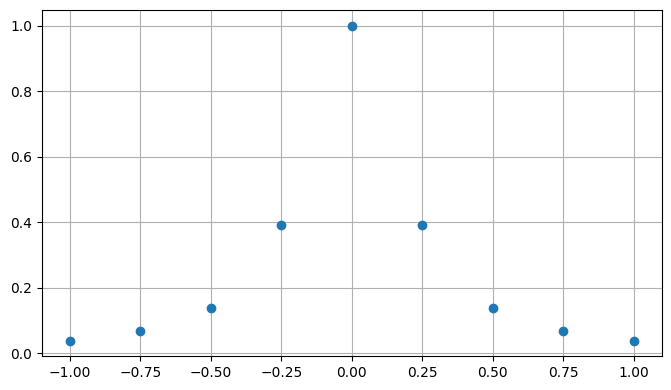

In [9]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

x = np.linspace(-1.0, 1.0, 9)
y = runge(x)
plt.plot(x, y, 'o')
plt.show()

Для графиков и оценки погрешности нам понадобится мелкая сетка `t` на том же отрезке. Нарисуем на ней саму функцию вместе с узлами.

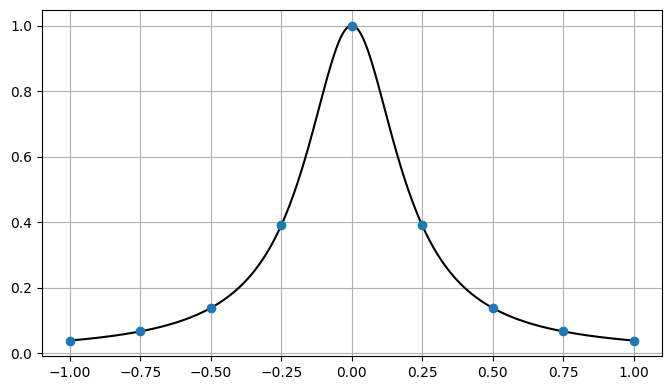

In [10]:
a, b = -1.0, 1.0
t = np.linspace(a, b, 2001)

plt.plot(t, runge(t), 'k')
plt.plot(x, y, 'o')
plt.show()

Существуют два принципиально разных подхода к интерполяции.

**Глобальная интерполяция.** Одна функция на всём отрезке, например многочлен степени $n$, проходящий через все $n+1$ точек.

**Локальная (кусочная) интерполяция.** На каждом отрезке $[x_{i-1}, x_i]$ строится своя простая функция, использующая только соседние узлы.

## 2. Глобальная интерполяция: многочлен Ньютона

Напомним, что интерполяционный многочлен степени $n$ по $n+1$ точкам существует и единственен. Его удобно записывать в форме Ньютона:

$$P_n(x) = f[x_0] + f[x_0, x_1](x - x_0) + f[x_0, x_1, x_2](x - x_0)(x - x_1) + \dots + f[x_0, \dots, x_n]\prod_{k=0}^{n-1}(x - x_k),$$

где разделённые разности определяются рекуррентно:

$$f[x_i] = y_i, \qquad f[x_i, \dots, x_{i+k}] = \frac{f[x_{i+1}, \dots, x_{i+k}] - f[x_i, \dots, x_{i+k-1}]}{x_{i+k} - x_i}.$$

Коэффициенты $c_k = f[x_0, \dots, x_k]$ вычисляются по таблице разделённых разностей «на месте» (в одном массиве), а значение многочлена — по схеме Горнера:

$$P_n(x) = c_0 + (x - x_0)\Big(c_1 + (x - x_1)\big(c_2 + \dots + (x - x_{n-1})c_n\big)\Big).$$

Функции для вычисления коэффициентов и значений многочлена уже написаны. Запустите ячейку.

In [11]:
def newton_coeff(x, y):
    # Коэффициенты многочлена Ньютона c_k = f[x_0, ..., x_k]
    n = len(x)
    c = np.array(y, dtype=float)
    for k in range(1, n):
        # после шага k в c[i] (i >= k) лежит f[x_{i-k}, ..., x_i]
        c[k:] = (c[k:] - c[k-1:n-1]) / (x[k:] - x[:n-k])
    return c


def newton_eval(c, x, t):
    # Значение многочлена Ньютона в точках t (схема Горнера)
    n = len(x) - 1
    p = c[n] * np.ones_like(t, dtype=float)
    for k in range(n - 1, -1, -1):
        p = p * (t - x[k]) + c[k]
    return p

> **Для преподавателя.** Объясните только, что делает каждая функция и что она принимает и возвращает: `newton_coeff(x, y)` по узлам и значениям возвращает массив коэффициентов, `newton_eval(c, x, t)` по коэффициентам и узлам вычисляет многочлен в точках `t`. Внутренности можно кратко связать с формулами выше, не разбирая срезы.

### Феномен Рунге

Построим интерполяционный многочлен по равноотстоящим узлам. Интуиция подсказывает, что чем больше узлов, тем точнее приближение. Проверим.

In [14]:
n = 16
x = np.linspace(a, b, n + 1)
c = newton_coeff(x, runge(x))
P = newton_eval(c, x, t)

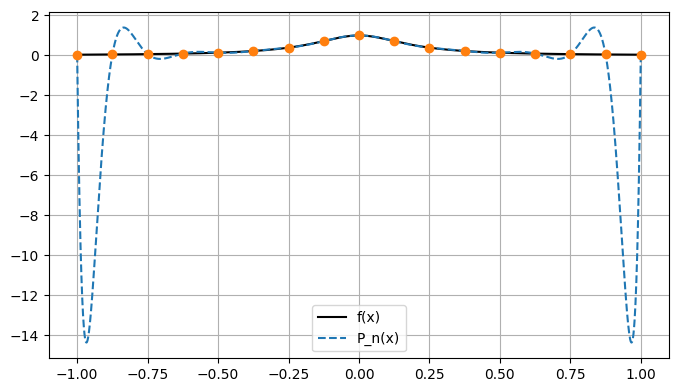

14.39385128501289


In [15]:
plt.plot(t, runge(t), 'k', label='f(x)')
plt.plot(t, P, '--', label='P_n(x)')
plt.plot(x, runge(x), 'o')
plt.legend()
plt.show()

err = np.max(np.abs(P - runge(t)))
print(err)

**Мини-задача.** Меняйте `n` в ячейке выше (6, 8, 10, 12, ...) и перезапускайте обе ячейки. Что происходит с графиком? При каком чётном $n$ погрешность впервые превышает 10?

> **Для преподавателя.** Перед первым изменением n спросите аудиторию: «Что будет при увеличении n?». Большинство ответит, что станет лучше.
> 
> Ответ на мини-задачу: n = 16 (погрешность около 14.4). Если кто-то попробует нечётные n, он увидит, что погрешность там заметно меньше (n = 15 даёт около 2.1): при нечётном n узла в нуле нет. Рост всё равно есть, просто медленнее. Поэтому в задаче сказано «чётное n».
> 
> Не поднимайте n выше 20–25: при большом числе равноотстоящих узлов к феномену Рунге добавляются ошибки округления в разделённых разностях.

Та же картина для нескольких $n$ сразу и таблица погрешностей (просто запустите):

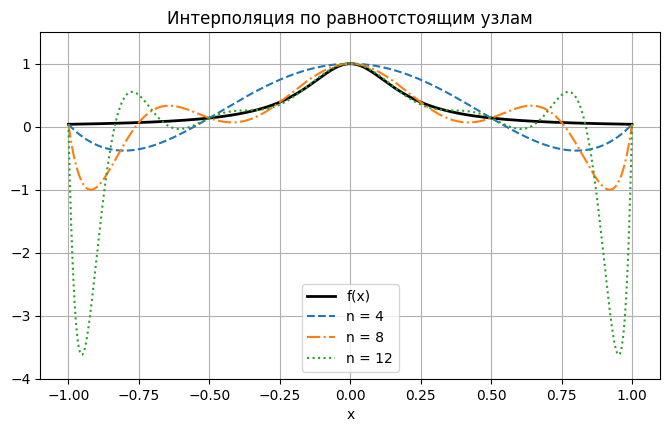

 n    max|f - P_n|
 2    6.462e-01
 4    4.384e-01
 6    6.169e-01
 8    1.045e+00
10    1.916e+00
12    3.663e+00
14    7.195e+00
16    1.439e+01
18    2.919e+01
20    5.982e+01


In [16]:
plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 12], ['--', '-.', ':']):
    x = np.linspace(a, b, n + 1)
    c = newton_coeff(x, runge(x))
    plt.plot(t, newton_eval(c, x, t), style, label=f'n = {n}')
plt.ylim(-4, 1.5)
plt.xlabel('x')
plt.title('Интерполяция по равноотстоящим узлам')
plt.legend()
plt.show()

print(' n    max|f - P_n|')
for n in range(2, 21, 2):
    x = np.linspace(a, b, n + 1)
    c = newton_coeff(x, runge(x))
    err = np.max(np.abs(newton_eval(c, x, t) - runge(t)))
    print(f'{n:2d}   {err:10.3e}')

**Феномен Рунге.** При увеличении числа равноотстоящих узлов интерполяционный многочлен не сходится к функции Рунге: у краёв отрезка возникают осцилляции, амплитуда которых растёт с ростом $n$.

Объяснение даёт формула остаточного члена интерполяции:

$$f(x) - P_n(x) = \frac{f^{(n+1)}(\xi)}{(n+1)!}\,\omega_{n+1}(x), \qquad \omega_{n+1}(x) = \prod_{i=0}^{n}(x - x_i).$$

У функции Рунге производные растут очень быстро (быстрее, чем $(n+1)!$ компенсирует), а на равномерной сетке $|\omega_{n+1}(x)|$ велико у краёв отрезка.

Отсюда два пути:
1. Уменьшить $\max|\omega_{n+1}(x)|$ за счёт выбора узлов.
2. Не повышать степень многочлена, а перейти к локальной интерполяции.

## 3. Путь первый: узлы Чебышёва

Величина $\max_{[a,b]}|\omega_{n+1}(x)|$ минимальна, если в качестве узлов взять корни многочлена Чебышёва $T_{n+1}$, пересчитанные на отрезок $[a, b]$:

$$x_k = \frac{a + b}{2} + \frac{b - a}{2}\cos\frac{\pi(2k + 1)}{2(n + 1)}, \qquad k = 0, 1, \dots, n.$$

Вычислим узлы по этой формуле и сравним их расположение с равноотстоящими.

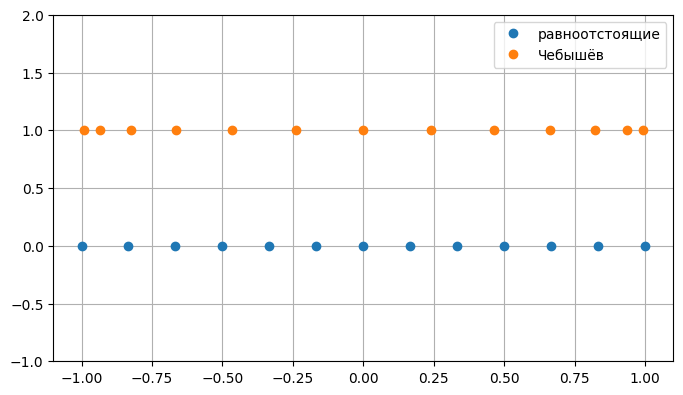

In [8]:
n = 12
k = np.arange(n + 1)
x_cheb = 0.5 * (a + b) + 0.5 * (b - a) * np.cos(np.pi * (2 * k + 1) / (2 * (n + 1)))
x_uni = np.linspace(a, b, n + 1)

plt.plot(x_uni, np.zeros_like(x_uni), 'o', label='равноотстоящие')
plt.plot(x_cheb, np.ones_like(x_cheb), 'o', label='Чебышёв')
plt.ylim(-1, 2)
plt.legend()
plt.show()

Узлы Чебышёва сгущаются к краям отрезка, как раз там, где на равномерной сетке возникали осцилляции. Построим по ним многочлен.

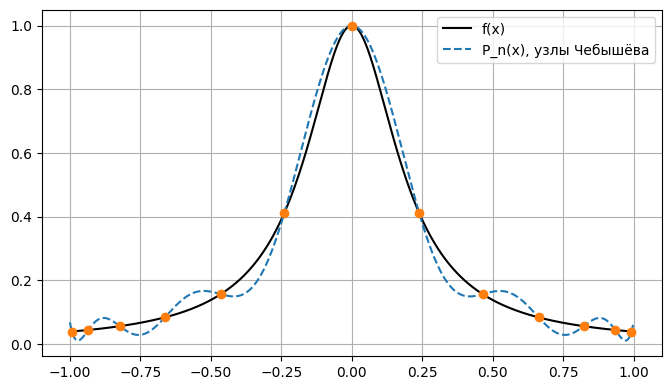

0.06921570780776642


In [9]:
c = newton_coeff(x_cheb, runge(x_cheb))
P = newton_eval(c, x_cheb, t)

plt.plot(t, runge(t), 'k', label='f(x)')
plt.plot(t, P, '--', label='P_n(x), узлы Чебышёва')
plt.plot(x_cheb, runge(x_cheb), 'o')
plt.legend()
plt.show()

print(np.max(np.abs(P - runge(t))))

То же для нескольких $n$ и таблица погрешностей (просто запустите):

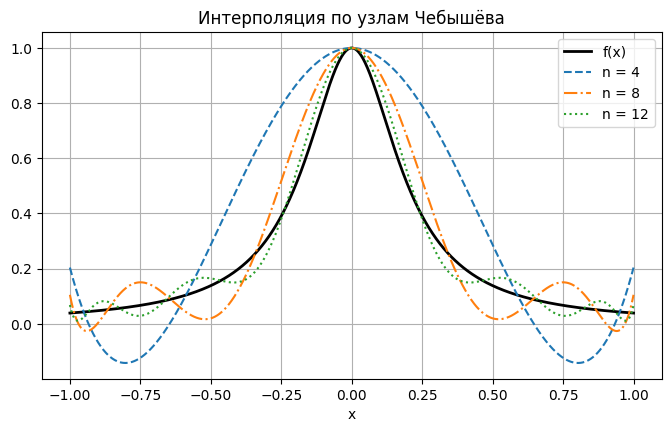

 n    max|f - P_n|
 2    6.006e-01
 4    4.020e-01
 6    2.642e-01
 8    1.708e-01
10    1.092e-01
12    6.922e-02
14    4.660e-02
16    3.261e-02
18    2.249e-02
20    1.533e-02


In [10]:
def chebyshev_nodes(a, b, n):
    # n + 1 узлов Чебышёва на [a, b]
    k = np.arange(n + 1)
    return 0.5 * (a + b) + 0.5 * (b - a) * np.cos(np.pi * (2 * k + 1) / (2 * (n + 1)))


plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 12], ['--', '-.', ':']):
    x = chebyshev_nodes(a, b, n)
    c = newton_coeff(x, runge(x))
    plt.plot(t, newton_eval(c, x, t), style, label=f'n = {n}')
plt.xlabel('x')
plt.title('Интерполяция по узлам Чебышёва')
plt.legend()
plt.show()

print(' n    max|f - P_n|')
for n in range(2, 21, 2):
    x = chebyshev_nodes(a, b, n)
    c = newton_coeff(x, runge(x))
    print(f'{n:2d}   {np.max(np.abs(newton_eval(c, x, t) - runge(t))):10.3e}')

**Запасной материал.** Важна не конкретная формула Чебышёва, а сгущение узлов к краям. Например, узлы можно сгустить к краям с помощью гиперболического тангенса. Эта ячейка есть только в версии преподавателя.

равномерные  max|f - P_n| = 3.663e+00
tanh         max|f - P_n| = 9.054e-02
Чебышёв      max|f - P_n| = 6.922e-02


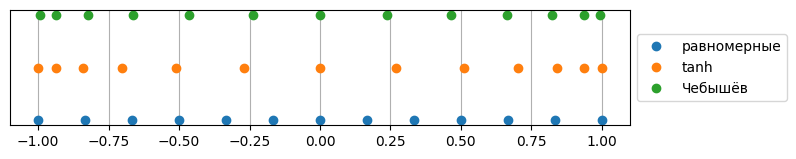

In [11]:
def tanh_nodes(a, b, n, beta=3.0):
    # Сгущение узлов к краям: отображение s(xi) растёт быстрее всего в центре,
    # поэтому в центре шаг большой, а у краёв маленький
    xi = np.linspace(0.0, 1.0, n + 1)
    s = 0.5 * (1.0 + np.tanh(beta * (xi - 0.5)) / np.tanh(0.5 * beta))
    return a + (b - a) * s


n = 12
fig, ax = plt.subplots(figsize=(8, 1.5))
for row, (name, x) in enumerate([('равномерные', np.linspace(a, b, n + 1)),
                                 ('tanh', tanh_nodes(a, b, n)),
                                 ('Чебышёв', chebyshev_nodes(a, b, n))]):
    ax.plot(x, 0 * x + row, 'o', label=name)
    c = newton_coeff(x, runge(x))
    print(f'{name:12s} max|f - P_n| = {np.max(np.abs(newton_eval(c, x, t) - runge(t))):.3e}')
ax.set_yticks([])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

**Почему узлов Чебышёва недостаточно?**

1. Узлы Чебышёва помогают, только если мы сами выбираем, где вычислять функцию. На практике данные часто заданы на фиксированной сетке: измерения, таблицы, результаты другого расчёта.
2. Глобальность: изменение одного значения $y_i$ меняет интерполяционный многочлен на всём отрезке (это увидим чуть ниже).
3. Многочлены высокой степени чувствительны к ошибкам в данных и к ошибкам округления.

Поэтому переходим ко второму пути — локальной интерполяции.

## 4. Путь второй: кусочно-линейная интерполяция

Самый простой вариант локальной интерполяции: на каждом отрезке $[x_{i-1}, x_i]$ соединяем соседние точки прямой:

$$g(x) = y_{i-1}\frac{x_i - x}{h_i} + y_i\frac{x - x_{i-1}}{h_i}, \qquad h_i = x_i - x_{i-1}.$$

Оценка погрешности для $f \in C^2[a, b]$ и $h = \max h_i$:

$$\max_{[a,b]}|f(x) - g(x)| \le \frac{h^2}{8}\max_{[a,b]}|f''(x)|.$$

Погрешность стремится к нулю при $h \to 0$ для любой дважды гладкой функции, никакого феномена Рунге нет. В `numpy` такая интерполяция уже реализована: `np.interp(t, x, y)` вычисляет значения ломаной, проходящей через точки `(x, y)`, в точках `t`.

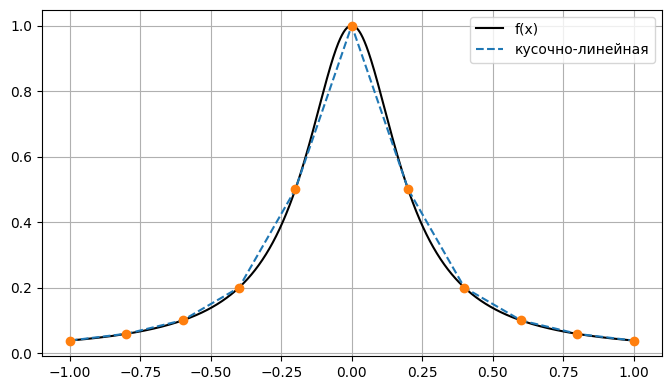

0.06744204365124995


In [12]:
n = 10
x = np.linspace(a, b, n + 1)
g = np.interp(t, x, runge(x))

plt.plot(t, runge(t), 'k', label='f(x)')
plt.plot(t, g, '--', label='кусочно-линейная')
plt.plot(x, runge(x), 'o')
plt.legend()
plt.show()

print(np.max(np.abs(g - runge(t))))

**Мини-задача.** Для функции $\sin x$ на отрезке $[0, \pi]$ вычислите максимальную погрешность кусочно-линейной интерполяции при $n = 10$ и $n = 20$ (не забудьте создать для этого отрезка свою мелкую сетку). Во сколько раз уменьшилась погрешность? Согласуется ли это с оценкой $O(h^2)$?

In [13]:
ts = np.linspace(0, np.pi, 10001)

x10 = np.linspace(0, np.pi, 11)
e10 = np.max(np.abs(np.interp(ts, x10, np.sin(x10)) - np.sin(ts)))

x20 = np.linspace(0, np.pi, 21)
e20 = np.max(np.abs(np.interp(ts, x20, np.sin(x20)) - np.sin(ts)))

print(e10, e20, e10 / e20)

0.01216029118505424 0.0030731634355590787 3.9569295418360997


*Ответ.* Погрешность уменьшается примерно в 4 раза: шаг уменьшился в 2 раза, а погрешность пропорциональна $h^2$.

Таблица погрешностей для функции Рунге (просто запустите):

In [14]:
print('  n    max|f - g|')
for n in [4, 8, 16, 32, 64, 128]:
    x = np.linspace(a, b, n + 1)
    print(f'{n:3d}   {np.max(np.abs(np.interp(t, x, runge(x)) - runge(t))):10.3e}')

  n    max|f - g|
  4    1.802e-01
  8    6.390e-02
 16    5.355e-02
 32    2.070e-02
 64    5.846e-03
128    1.509e-03


**Локальность.** Изменим одно значение $y_3$ и посмотрим, как изменятся интерполяционный многочлен и кусочно-линейная интерполяция (просто запустите).

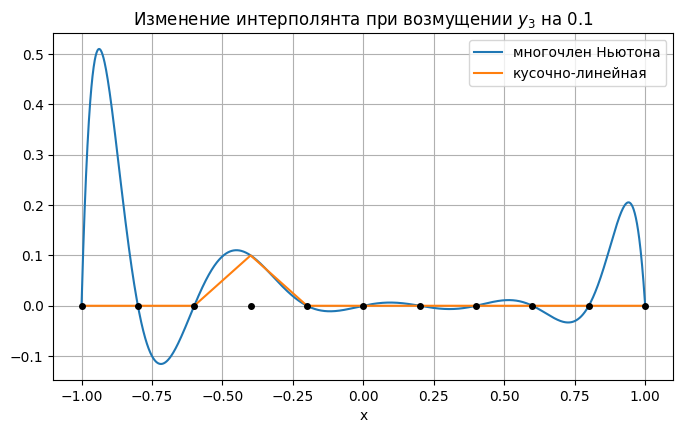

In [15]:
n = 10
x = np.linspace(a, b, n + 1)
y = runge(x)
y_pert = y.copy()
y_pert[3] += 0.1            # возмущаем одно значение

dP = newton_eval(newton_coeff(x, y_pert), x, t) - newton_eval(newton_coeff(x, y), x, t)
dL = np.interp(t, x, y_pert) - np.interp(t, x, y)

plt.plot(t, dP, label='многочлен Ньютона')
plt.plot(t, dL, label='кусочно-линейная')
plt.plot(x, 0 * x, 'ko', ms=4)
plt.xlabel('x')
plt.title('Изменение интерполянта при возмущении $y_3$ на 0.1')
plt.legend()
plt.show()

Изменение многочлена «расползается» на весь отрезок, а кусочно-линейная интерполяция меняется только на двух соседних отрезках.

**Недостаток кусочно-линейной интерполяции** — изломы в узлах: первая производная разрывна. Для многих задач это неприемлемо: например, если по интерполянту нужно вычислять производные (тепловой поток, скорость) или если нужна гладкая кривая в графике и геометрии.

## 5. Кубический сплайн

### Почему кубический?

Хотим сохранить локальность, но избавиться от изломов. Для этого берём на каждом отрезке многочлен более высокой степени и требуем непрерывности производных в узлах.

Кубический сплайн — минимальная степень, при которой непрерывна вторая производная, то есть кривизна. Именно тогда график выглядит гладким на глаз. Квадратичные сплайны требуют одного дополнительного условия на одном из концов и ведут себя несимметрично, поэтому на практике почти не используются.

Кстати, кусочно-линейная интерполяция — это тоже сплайн, сплайн первой степени.

### Определение

**Кубическим сплайном**, интерполирующим данные $(x_i, y_i)$, называется функция $S(x)$, такая что:
1. на каждом отрезке $[x_{i-1}, x_i]$, $i = 1, \dots, n$, $S(x)$ — многочлен степени не выше 3;
2. $S(x_i) = y_i$, $i = 0, \dots, n$;
3. $S(x) \in C^2[a, b]$, то есть $S$, $S'$ и $S''$ непрерывны во внутренних узлах $x_1, \dots, x_{n-1}$.

### Подсчёт условий

Неизвестных: по 4 коэффициента на каждый из $n$ отрезков, итого $4n$.

Условий:
- интерполяция на обоих концах каждого отрезка: $2n$;
- непрерывность $S'$ во внутренних узлах: $n - 1$;
- непрерывность $S''$ во внутренних узлах: $n - 1$.

Итого $4n - 2$ условия. **Не хватает двух условий** — их задают на концах отрезка. Это граничные условия.

> **Для преподавателя.** Прежде чем показать подсчёт, спросите студентов: «Сколько неизвестных? Сколько условий?». Пусть посчитают сами.

### Типы граничных условий

1. **Естественный (натуральный) сплайн:** $S''(a) = S''(b) = 0$.
2. **Закреплённый сплайн (clamped):** заданы производные на концах, $S'(a) = f'(a)$, $S'(b) = f'(b)$.
3. **Условие «not-a-knot»:** третья производная непрерывна в узлах $x_1$ и $x_{n-1}$. Тогда на первых двух и на последних двух отрезках сплайн — один и тот же многочлен, то есть $x_1$ и $x_{n-1}$ «не являются узлами».
4. **Периодический сплайн:** $S'(a) = S'(b)$, $S''(a) = S''(b)$ (при $y_0 = y_n$). Нужен для периодических функций и замкнутых кривых.

### Чем хорош естественный сплайн

Он не требует знания производных $f$ на концах, а только значений в узлах. Кроме того, он обладает **свойством минимальной кривизны**: среди всех функций $g \in C^2[a, b]$, проходящих через заданные точки, естественный сплайн минимизирует функционал

$$\int_a^b \big(g''(x)\big)^2\,dx.$$

Физический смысл: так изгибается тонкая упругая линейка, закреплённая в точках (энергия изгиба пропорциональна интегралу квадрата кривизны). Английское слово *spline* и означало такую чертёжную линейку.

### Оценки погрешности

Если $f \in C^4[a, b]$ и сплайн закреплённый (или not-a-knot), то

$$\max_{[a,b]}|f - S| \le \frac{5}{384}h^4\max_{[a,b]}|f^{(4)}|, \qquad \max|f' - S'| = O(h^3), \qquad \max|f'' - S''| = O(h^2).$$

Для естественного сплайна всё не так просто, и это мы исследуем в задаче 2.

> **Для преподавателя.** Не раскрывайте заранее, что у естественного сплайна порядок у границ падает до O(h²), если f'' на концах не ноль. Это студенты увидят сами в задаче 2. В итогах вернитесь к этому: в начале хвалили естественный сплайн, в конце нашли его слабое место.

### Кубический сплайн в `scipy`

Прежде чем разбираться, как устроен сплайн внутри, воспользуемся готовой реализацией `scipy.interpolate.CubicSpline`:

```python
cs = CubicSpline(x, y, bc_type='natural')   # построить сплайн
cs(t)                                       # значения сплайна в точках t
cs(t, 1)                                    # первая производная S'(t)
cs(t, 2)                                    # вторая производная S''(t)
```

Граничные условия задаются параметром `bc_type`:
- `'natural'` — естественный сплайн;
- `'not-a-knot'` — используется по умолчанию, если `bc_type` не указан;
- `bc_type=((1, df_a), (1, df_b))` — закреплённый сплайн с производными `df_a` и `df_b` на концах;
- `'periodic'` — периодический.

In [16]:
n = 8
x = np.linspace(a, b, n + 1)
y = runge(x)

cs_nat = CubicSpline(x, y, bc_type='natural')
cs_nak = CubicSpline(x, y)

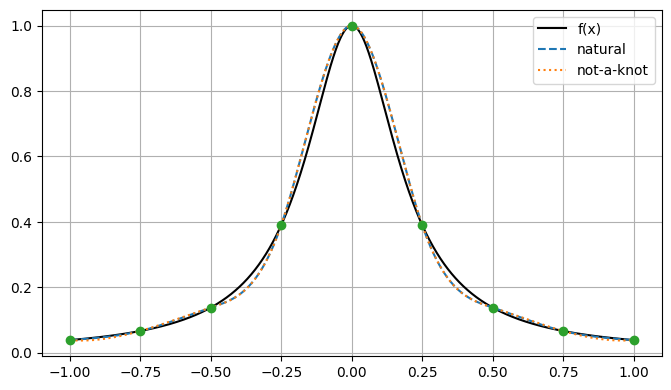

In [17]:
plt.plot(t, runge(t), 'k', label='f(x)')
plt.plot(t, cs_nat(t), '--', label='natural')
plt.plot(t, cs_nak(t), ':', label='not-a-knot')
plt.plot(x, y, 'o')
plt.legend()
plt.show()

**Мини-задача.** Поменяйте `n` в ячейке выше на 12, 16, 32 и перезапустите обе ячейки. Есть ли феномен Рунге?

Сплайны на графике почти совпадают. Нарисуем их разность, чтобы увидеть, где они отличаются.

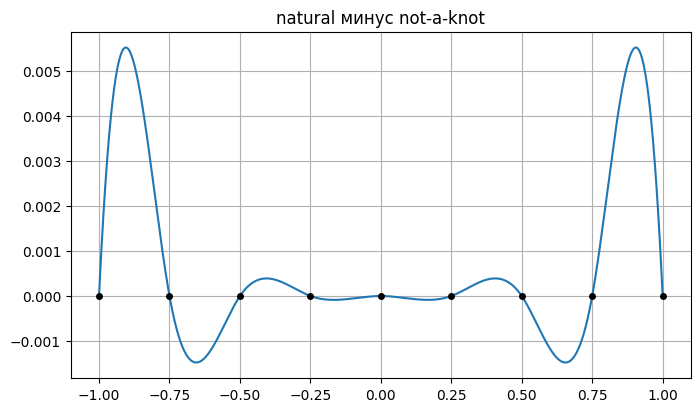

In [18]:
plt.plot(t, cs_nat(t) - cs_nak(t))
plt.plot(x, np.zeros_like(x), 'ko', ms=4)
plt.title('natural минус not-a-knot')
plt.show()

Сплайны отличаются в основном у краёв отрезка: граничные условия влияют прежде всего на поведение вблизи концов.

Теперь посмотрим на вторую производную сплайна.

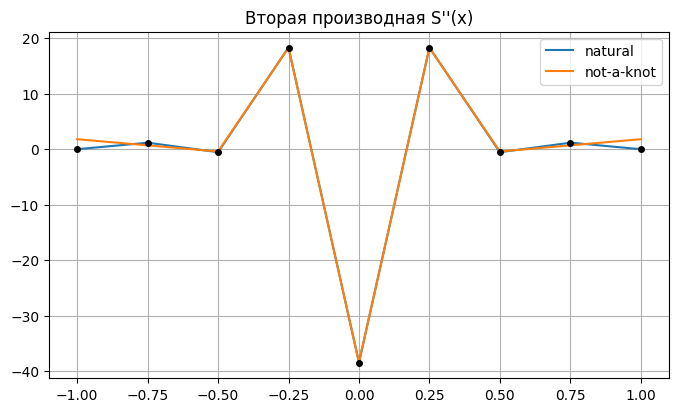

In [19]:
plt.plot(t, cs_nat(t, 2), label='natural')
plt.plot(t, cs_nak(t, 2), label='not-a-knot')
plt.plot(x, cs_nat(x, 2), 'ko', ms=4)
plt.legend()
plt.title("Вторая производная S''(x)")
plt.show()

Вторая производная кубического сплайна — **ломаная**: на каждом отрезке кубический многочлен, значит, его вторая производная линейна. У естественного сплайна она равна нулю на концах.

Отсюда идея: если знать значения $S''$ в узлах, то $S''$ восстанавливается на всём отрезке, а вместе с ней и сам сплайн. Эти значения называются **моментами** сплайна. Именно на этом основан способ построения сплайна, который мы сейчас выведем.

## 6. Вывод системы уравнений: метод моментов

Обозначим **моменты** сплайна $M_i = S''(x_i)$, $i = 0, \dots, n$, и шаги $h_i = x_i - x_{i-1}$, $i = 1, \dots, n$.

**Шаг 1.** На отрезке $[x_{i-1}, x_i]$ сплайн — кубический многочлен, значит $S''$ линейна:

$$S''(x) = M_{i-1}\frac{x_i - x}{h_i} + M_i\frac{x - x_{i-1}}{h_i}.$$

Непрерывность $S''$ в узлах выполнена автоматически: в каждом узле $x_i$ оба соседних отрезка дают $M_i$.

**Шаг 2.** Интегрируем дважды и подбираем две константы интегрирования из условий $S(x_{i-1}) = y_{i-1}$, $S(x_i) = y_i$:

$$\boxed{S(x) = M_{i-1}\frac{(x_i - x)^3}{6h_i} + M_i\frac{(x - x_{i-1})^3}{6h_i} + \left(y_{i-1} - \frac{M_{i-1}h_i^2}{6}\right)\frac{x_i - x}{h_i} + \left(y_i - \frac{M_i h_i^2}{6}\right)\frac{x - x_{i-1}}{h_i}}$$

Интерполяционные условия теперь тоже выполнены автоматически. Осталось обеспечить непрерывность $S'$.

**Шаг 3.** Дифференцируем:

$$S'(x) = -M_{i-1}\frac{(x_i - x)^2}{2h_i} + M_i\frac{(x - x_{i-1})^2}{2h_i} + \frac{y_i - y_{i-1}}{h_i} - \frac{(M_i - M_{i-1})h_i}{6}.$$

Производная слева в узле $x_i$ (отрезок $i$) и справа (отрезок $i+1$):

$$S'(x_i - 0) = \frac{h_i}{6}M_{i-1} + \frac{h_i}{3}M_i + \frac{y_i - y_{i-1}}{h_i}, \qquad
S'(x_i + 0) = -\frac{h_{i+1}}{3}M_i - \frac{h_{i+1}}{6}M_{i+1} + \frac{y_{i+1} - y_i}{h_{i+1}}.$$

**Шаг 4.** Приравниваем и умножаем на 6. Получаем для $i = 1, \dots, n-1$:

$$\boxed{h_i M_{i-1} + 2(h_i + h_{i+1}) M_i + h_{i+1} M_{i+1} = 6\left(\frac{y_{i+1} - y_i}{h_{i+1}} - \frac{y_i - y_{i-1}}{h_i}\right)}$$

Это $n - 1$ уравнение на $n + 1$ неизвестную. Два недостающих уравнения дают граничные условия. Для естественного сплайна $M_0 = 0$, $M_n = 0$.

### Матричная форма (естественный сплайн)

Удобно оставить все $n+1$ неизвестных и записать граничные условия как первую и последнюю строки системы:

$$
\begin{pmatrix}
1 & 0 & & & & \\
h_1 & 2(h_1 + h_2) & h_2 & & & \\
 & h_2 & 2(h_2 + h_3) & h_3 & & \\
 & & \ddots & \ddots & \ddots & \\
 & & & h_{n-1} & 2(h_{n-1} + h_n) & h_n \\
 & & & & 0 & 1
\end{pmatrix}
\begin{pmatrix} M_0 \\ M_1 \\ M_2 \\ \vdots \\ M_{n-1} \\ M_n \end{pmatrix}
=
\begin{pmatrix} 0 \\ d_1 \\ d_2 \\ \vdots \\ d_{n-1} \\ 0 \end{pmatrix},
\qquad d_i = 6\left(\frac{y_{i+1} - y_i}{h_{i+1}} - \frac{y_i - y_{i-1}}{h_i}\right).
$$

Плюс такой записи: для других граничных условий меняются только первая и последняя строки.

### Свойства матрицы

Матрица **трёхдиагональная**. Кроме того, у неё **строгое диагональное преобладание** по строкам:

$$2(h_i + h_{i+1}) > h_i + h_{i+1}, \qquad \text{а в граничных строках } 1 > 0.$$

По теореме Гершгорина все собственные значения лежат в кругах с центрами $a_{ii}$ и радиусами $\sum_{j \ne i}|a_{ij}| < |a_{ii}|$, поэтому ноль не является собственным значением. Следовательно, **матрица невырождена, и сплайн существует и единственен.**

Для трёхдиагональных систем существует быстрый метод решения за $O(n)$ операций — метод прогонки (см. приложение). Диагональное преобладание гарантирует его устойчивость. На семинаре мы для простоты будем решать систему стандартной функцией `np.linalg.solve`.

> **Для преподавателя.** Этот раздел — только теория, студенты ничего не печатают. Если отстаёте от графика, покажите итоговую систему в рамке и матрицу, а вывод предложите прочитать дома.

## 7. Собственная реализация естественного сплайна

Ниже три готовые функции:
- `natural_spline_system(x, y)` собирает матрицу $A$ и правую часть $d$ системы для моментов;
- `natural_spline(x, y)` решает систему и возвращает моменты $M_0, \dots, M_n$;
- `spline_eval(x, y, M, t)` вычисляет значения сплайна в точках `t` по формуле в рамке из раздела 6.

**Внимание к индексам.** В формулах $h_i = x_i - x_{i-1}$, $i = 1, \dots, n$. В коде `h = np.diff(x)` даёт `h[0] = x[1] - x[0]`, то есть $h_i$ хранится в `h[i-1]`.

**Поиск отрезка.** Для каждой точки $t$ нужно найти номер отрезка $i$, такой что $x_{i-1} \le t < x_i$. Это делается бинарным поиском, который в `numpy` для целого массива точек реализован функцией `np.searchsorted`.

Запустите ячейку.

In [20]:
def natural_spline_system(x, y):
    # Матрица A и правая часть d системы для моментов естественного сплайна
    n = len(x) - 1
    h = np.diff(x)                 # h[i-1] = h_i = x_i - x_{i-1}
    A = np.zeros((n + 1, n + 1))
    d = np.zeros(n + 1)
    A[0, 0] = 1.0                  # M_0 = 0
    A[n, n] = 1.0                  # M_n = 0
    for i in range(1, n):
        A[i, i - 1] = h[i - 1]
        A[i, i]     = 2.0 * (h[i - 1] + h[i])
        A[i, i + 1] = h[i]
        d[i] = 6.0 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
    return A, d


def natural_spline(x, y):
    # Моменты естественного сплайна
    A, d = natural_spline_system(x, y)
    return np.linalg.solve(A, d)


def spline_eval(x, y, M, t):
    # Значения кубического сплайна с моментами M в точках t
    t = np.asarray(t, dtype=float)
    # i такое, что x[i-1] <= t < x[i]; обрезаем, чтобы t = x_n попало в последний отрезок
    i = np.clip(np.searchsorted(x, t, side='right'), 1, len(x) - 1)
    h = x[i] - x[i - 1]
    left, right = x[i] - t, t - x[i - 1]
    return (M[i - 1] * left**3 + M[i] * right**3) / (6.0 * h) \
        + (y[i - 1] - M[i - 1] * h**2 / 6.0) * left / h \
        + (y[i] - M[i] * h**2 / 6.0) * right / h

> **Для преподавателя.** Пройдите по функции `natural_spline_system` построчно на проекторе и сопоставьте каждую строку с матрицей из раздела 6: первая и последняя строки — граничные условия, цикл — внутренние строки. В `spline_eval` достаточно объяснить идею: сначала для каждой точки находим номер отрезка, затем подставляем в формулу в рамке.

Посмотрим на матрицу для небольшой **неравномерной** сетки и проверим диагональное преобладание.

In [21]:
x = np.array([0.0, 0.3, 1.0, 1.4, 2.0])
y = np.sin(x)
A, d = natural_spline_system(x, y)
print(A)

[[1.  0.  0.  0.  0. ]
 [0.3 2.  0.7 0.  0. ]
 [0.  0.7 2.2 0.4 0. ]
 [0.  0.  0.4 2.  0.6]
 [0.  0.  0.  0.  1. ]]


In [22]:
diag = np.abs(np.diag(A))
off = np.sum(np.abs(A), axis=1) - diag
print(diag > off)

[ True  True  True  True  True]


Вычислим моменты и проверим, что сплайн проходит через узлы.

In [23]:
M = natural_spline(x, y)
print(M)
print(spline_eval(x, y, M, x) - y)

[ 0.    -0.335 -0.803 -1.3    0.   ]
[0. 0. 0. 0. 0.]


Сравним со `scipy`: моменты должны совпасть с `cs(x, 2)`, а значения — на мелкой сетке.

In [24]:
cs = CubicSpline(x, y, bc_type='natural')
print(M - cs(x, 2))

tt = np.linspace(0.0, 2.0, 1001)
print(np.max(np.abs(spline_eval(x, y, M, tt) - cs(tt))))

[-0.  0.  0. -0.  0.]
3.3306690738754696e-16


Совпадение с точностью до ошибок округления. Наконец, таблица погрешностей нашего сплайна и кусочно-линейной интерполяции для функции Рунге (просто запустите):

In [25]:
print('  n    сплайн       кусочно-линейная')
for n in [4, 8, 16, 32, 64, 128]:
    x = np.linspace(a, b, n + 1)
    y = runge(x)
    e_s = np.max(np.abs(spline_eval(x, y, natural_spline(x, y), t) - runge(t)))
    e_l = np.max(np.abs(np.interp(t, x, y) - runge(t)))
    print(f'{n:3d}   {e_s:10.3e}   {e_l:10.3e}')

  n    сплайн       кусочно-линейная
  4    2.793e-01    1.802e-01
  8    5.607e-02    6.390e-02
 16    3.745e-03    5.355e-02
 32    6.555e-04    2.070e-02
 64    4.032e-05    5.846e-03
128    2.522e-06    1.509e-03


Погрешность сплайна убывает с ростом числа узлов, и при достаточно большом $n$ сплайн намного точнее кусочно-линейной интерполяции при том же числе узлов.

---
## 8. Задачи

### Задача 1. Свои точки

1. Задайте 6–7 точек: либо значения $\sin x$ в нескольких узлах на $[0, 2\pi]$, либо любые придуманные вами числа.
2. Постройте по ним естественный сплайн и сплайн not-a-knot с помощью `CubicSpline`.
3. Нарисуйте оба сплайна и точки на одном графике, а на втором — их разность.
4. Где сплайны отличаются сильнее всего?

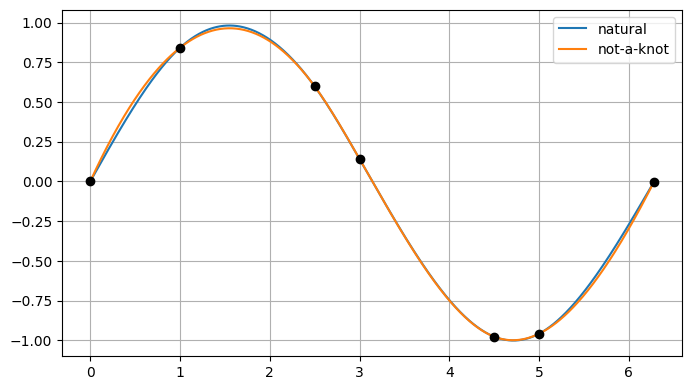

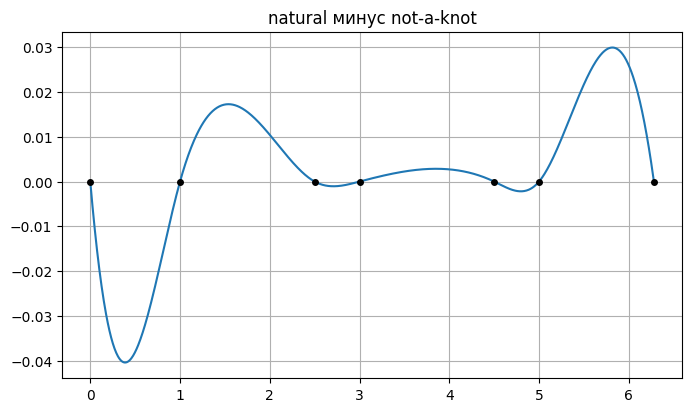

In [26]:
xp = np.array([0.0, 1.0, 2.5, 3.0, 4.5, 5.0, 6.28])
yp = np.sin(xp)
tp = np.linspace(xp[0], xp[-1], 1001)

s1 = CubicSpline(xp, yp, bc_type='natural')
s2 = CubicSpline(xp, yp)

plt.plot(tp, s1(tp), label='natural')
plt.plot(tp, s2(tp), label='not-a-knot')
plt.plot(xp, yp, 'ko')
plt.legend()
plt.show()

plt.plot(tp, s1(tp) - s2(tp))
plt.plot(xp, np.zeros_like(xp), 'ko', ms=4)
plt.title('natural минус not-a-knot')
plt.show()

*Ответ.* Сплайны сильнее всего отличаются на крайних отрезках, у концов интервала. В середине разность быстро затухает.

### Задача 2. Исследование сходимости

Рассмотрим функцию $f(x) = e^x$ на отрезке $[0, 1]$. Будем удваивать число отрезков $n$ и смотреть, во сколько раз уменьшается погрешность:
- если погрешность пропорциональна $h^2$, то при уменьшении шага вдвое она уменьшается в $2^2 = 4$ раза;
- если погрешность пропорциональна $h^4$, то в $2^4 = 16$ раз.

Функция `print_ratios` печатает таблицу погрешностей и отношения соседних погрешностей. Запустите ячейку с ней.

In [27]:
def print_ratios(ns, errors):
    # Таблица: n, погрешность, во сколько раз погрешность уменьшилась по сравнению с предыдущей
    print('   n     погрешность   отношение')
    for k in range(len(ns)):
        if k == 0:
            print(f'{ns[k]:4d}   {errors[k]:.3e}')
        else:
            print(f'{ns[k]:4d}   {errors[k]:.3e}     {errors[k - 1] / errors[k]:6.2f}')

1. Допишите в цикле строку, вычисляющую максимальную погрешность сплайна на мелкой сетке `tt`. Внимание: погрешность нужно считать именно на мелкой сетке, а не в узлах (в узлах она равна нулю).
2. Запустите ячейку для естественного сплайна. Во сколько раз уменьшается погрешность?
3. Замените `bc_type='natural'` на `bc_type='not-a-knot'`, а затем на закреплённый сплайн `bc_type=((1, 1.0), (1, np.e))` (производная $e^x$ на концах равна $1$ и $e$). Как изменились отношения?

In [28]:
ns = [4, 8, 16, 32, 64, 128]
tt = np.linspace(0.0, 1.0, 10001)
errors = []
for n in ns:
    x = np.linspace(0.0, 1.0, n + 1)
    cs = CubicSpline(x, np.exp(x), bc_type='natural')
    err = np.max(np.abs(cs(tt) - np.exp(tt)))
    errors.append(err)

print_ratios(ns, errors)

   n     погрешность   отношение
   4   8.217e-03
   8   2.081e-03       3.95
  16   5.210e-04       3.99
  32   1.303e-04       4.00
  64   3.258e-05       4.00
 128   8.144e-06       4.00


In [29]:
for bc in ['not-a-knot', ((1, 1.0), (1, np.e))]:
    errors = []
    for n in ns:
        x = np.linspace(0.0, 1.0, n + 1)
        cs = CubicSpline(x, np.exp(x), bc_type=bc)
        errors.append(np.max(np.abs(cs(tt) - np.exp(tt))))
    print(bc)
    print_ratios(ns, errors)
    print()

not-a-knot
   n     погрешность   отношение
   4   2.207e-04
   8   1.649e-05      13.38
  16   1.099e-06      15.00
  32   7.094e-08      15.49
  64   4.506e-09      15.74
 128   2.838e-10      15.87

((1, 1.0), (1, 2.718281828459045))
   n     погрешность   отношение
   4   2.636e-05
   8   1.690e-06      15.60
  16   1.069e-07      15.82
  32   6.716e-09      15.91
  64   4.208e-10      15.96
 128   2.634e-11      15.98



Все три случая на одном графике в двойном логарифмическом масштабе (просто запустите). Прямые $h^4$ и $h^2$ нарисованы для сравнения наклонов.

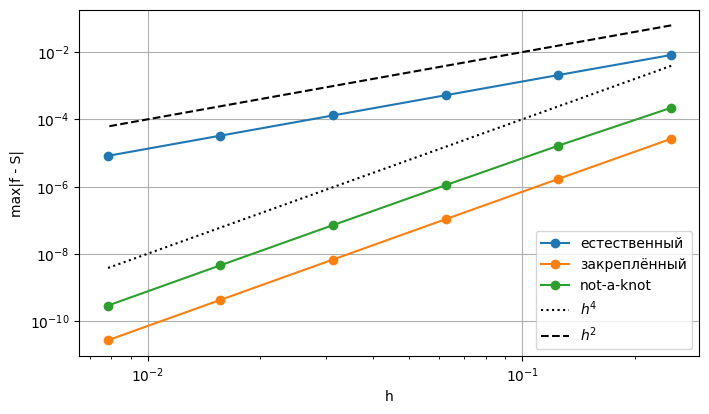

In [30]:
def convergence_plot(f, df, xa, xb, ns):
    tt = np.linspace(xa, xb, 20001)
    hs = [(xb - xa) / n for n in ns]
    cases = {'естественный': 'natural',
             'закреплённый': ((1, df(xa)), (1, df(xb))),
             'not-a-knot': 'not-a-knot'}
    for name, bc in cases.items():
        errs = []
        for n in ns:
            x = np.linspace(xa, xb, n + 1)
            errs.append(np.max(np.abs(CubicSpline(x, f(x), bc_type=bc)(tt) - f(tt))))
        plt.loglog(hs, errs, 'o-', label=name)
    hs = np.array(hs)
    plt.loglog(hs, hs**4, 'k:', label='$h^4$')
    plt.loglog(hs, hs**2, 'k--', label='$h^2$')
    plt.xlabel('h')
    plt.ylabel('max|f - S|')
    plt.legend()
    plt.show()


convergence_plot(np.exp, np.exp, 0.0, 1.0, ns)

4. Почему у естественного сплайна порядок хуже? Подсказка: чему равна вторая производная $e^x$ на концах отрезка и чему равна вторая производная естественного сплайна?
5. *(Для быстрых.)* Нарисуйте модуль погрешности естественного сплайна $|f(x) - S(x)|$ при $n = 32$ с помощью `plt.semilogy`. Где сосредоточена погрешность?
6. *(Для быстрых.)* Повторите исследование для $f(x) = \sin x$ на $[0, \pi]$, например с помощью `convergence_plot(np.sin, np.cos, 0.0, np.pi, ns)`. Что изменилось и почему?

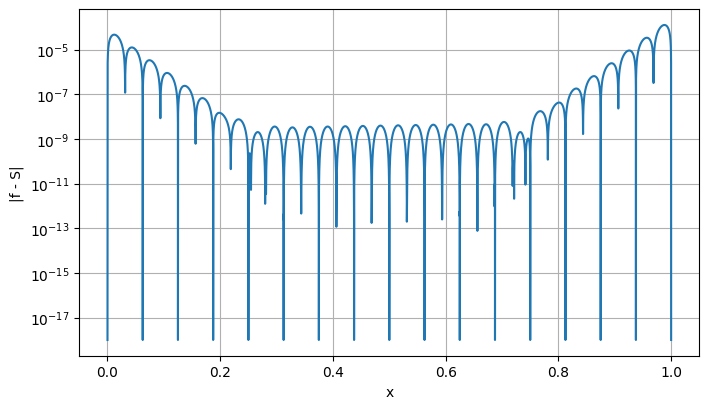

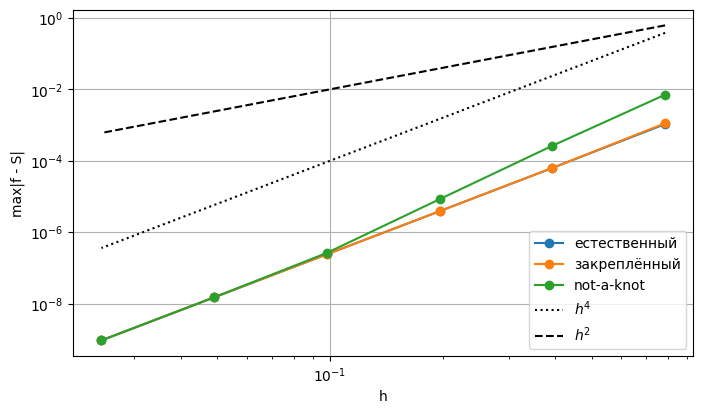

In [31]:
n = 32
x = np.linspace(0.0, 1.0, n + 1)
cs = CubicSpline(x, np.exp(x), bc_type='natural')
plt.semilogy(tt, np.abs(cs(tt) - np.exp(tt)) + 1e-18)
plt.xlabel('x')
plt.ylabel('|f - S|')
plt.show()

convergence_plot(np.sin, np.cos, 0.0, np.pi, ns)

*Ответ к задаче 2.* Для $e^x$ закреплённый и not-a-knot сплайны дают отношение около 16 (порядок 4), а естественный — около 4 (порядок 2). Условие $S''(a) = S''(b) = 0$ неверно для $e^x$ (у неё $f'' = e^x \ne 0$), и эта ошибка в граничном условии порождает погрешность $O(h^2)$ вблизи концов, которая быстро затухает вглубь отрезка. Для $\sin x$ на $[0, \pi]$ вторая производная на концах равна нулю, граничное условие естественного сплайна точное, и порядок 4 восстанавливается у всех трёх сплайнов.

Вывод: естественный сплайн хорош, когда о производных на концах ничего не известно, но если есть возможность, лучше использовать закреплённый сплайн или not-a-knot.

> **Для преподавателя.** Если кто-то получил отношения около 1 или ошибку порядка 1e-16, почти наверняка погрешность считается в узлах `x`, а не на мелкой сетке `tt`.

### Задача 3 (для быстрых). Замкнутая гладкая кривая

Через точки на плоскости, образующие замкнутый контур, можно провести гладкую замкнутую кривую с помощью периодического сплайна. Для этого координаты $x$ и $y$ записывают как функции параметра $s$ и строят сплайны $x(s)$ и $y(s)$.

1. Точки контура заданы ниже (последняя совпадает с первой).
2. Введите параметр $s$ — накопленную длину ломаной: $s_0 = 0$, $s_k = s_{k-1} + |P_k - P_{k-1}|$. Подсказка: длины звеньев — `np.hypot(np.diff(px), np.diff(py))`, накопленная сумма — `np.cumsum`, добавить ноль в начало — `np.concatenate(([0.0], ...))`.
3. Постройте сплайн сразу для обеих координат: `CubicSpline(s, np.column_stack((px, py)), bc_type='periodic')`. Его значения на сетке `ss` — массив из двух столбцов: `curve[:, 0]` и `curve[:, 1]`.
4. Нарисуйте кривую и точки (`plt.axis('equal')`, чтобы не было искажений).

Почему параметр удобно выбирать как длину ломаной, а не просто номер точки?

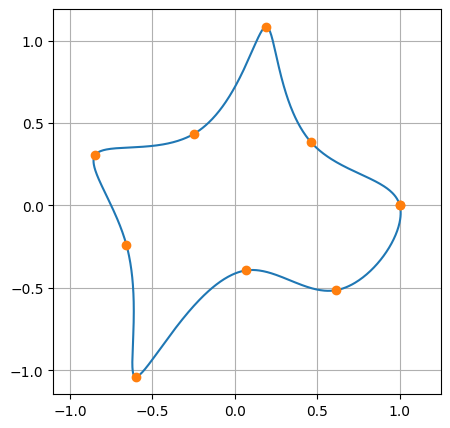

In [32]:
phi = np.linspace(0, 2 * np.pi, 10)[:-1]
r = np.array([1.0, 0.6, 1.1, 0.5, 0.9, 0.7, 1.2, 0.4, 0.8])
px = np.concatenate((r * np.cos(phi), [r[0]]))
py = np.concatenate((r * np.sin(phi), [0.0]))

s = np.concatenate(([0.0], np.cumsum(np.hypot(np.diff(px), np.diff(py)))))
cs = CubicSpline(s, np.column_stack((px, py)), bc_type='periodic')
ss = np.linspace(0, s[-1], 1000)
curve = cs(ss)

plt.figure(figsize=(5, 5))
plt.plot(curve[:, 0], curve[:, 1])
plt.plot(px, py, 'o')
plt.axis('equal')
plt.show()

*Ответ.* Если параметр — номер точки, то соседние точки, расположенные близко и далеко, получают одинаковый «шаг» параметра, и на коротких звеньях кривая делает лишние петли, а на длинных слишком «натягивается». Длина ломаной приближённо соответствует длине дуги, и скорость движения по кривой получается примерно равномерной.

### Задача 4 (для быстрых). Насколько локален кубический сплайн?

Строго говоря, кубический сплайн не является локальным: система связывает все моменты, и изменение одного $y_i$ меняет сплайн на всём отрезке. Но насколько сильно?

1. Возьмите $n = 20$ равноотстоящих отрезков на $[-1, 1]$ и значения функции Рунге. Измените одно значение $y_{10}$ на $0.1$ (заготовка ниже).
2. Вычислите изменение естественного сплайна $\Delta S(t)$ и изменение многочлена Ньютона $\Delta P(t)$ на сетке `t`.
3. Нарисуйте $|\Delta S|$ и $|\Delta P|$ в логарифмическом масштабе (`plt.semilogy`). Как ведёт себя $|\Delta S|$ при удалении от возмущённого узла?

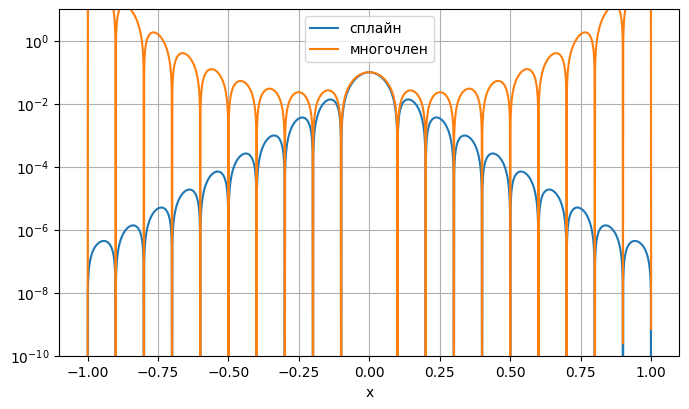

In [33]:
n = 20
x = np.linspace(a, b, n + 1)
y = runge(x)
y_pert = y.copy()
y_pert[10] = y_pert[10] + 0.1

dS = CubicSpline(x, y_pert, bc_type='natural')(t) - CubicSpline(x, y, bc_type='natural')(t)
dP = newton_eval(newton_coeff(x, y_pert), x, t) - newton_eval(newton_coeff(x, y), x, t)

plt.semilogy(t, np.abs(dS) + 1e-18, label='сплайн')
plt.semilogy(t, np.abs(dP) + 1e-18, label='многочлен')
plt.ylim(1e-10, 10)
plt.xlabel('x')
plt.legend()
plt.show()

*Ответ.* $|\Delta S|$ убывает экспоненциально: на равномерной сетке вдали от возмущения моменты удовлетворяют однородному уравнению $M_{i-1} + 4M_i + M_{i+1} = 0$, затухающее решение которого $M_i \sim \lambda^i$ с $\lambda = -2 + \sqrt{3} \approx -0.27$. Возмущение уменьшается примерно в 3.7 раза на каждом отрезке. Сплайн «почти локален», а строго локальными являются B-сплайны.

---
## Итоги

- Глобальная интерполяция многочленом высокой степени по равноотстоящим узлам может расходиться (феномен Рунге).
- Узлы Чебышёва решают проблему, но только если узлы можно выбирать.
- Локальная интерполяция сходится при уменьшении шага. Кусочно-линейная даёт порядок $O(h^2)$, но имеет изломы.
- Кубический сплайн — гладкая ($C^2$) кусочно-кубическая функция. Для его построения нужно решить трёхдиагональную систему с диагональным преобладанием.
- Порядок точности сплайна $O(h^4)$ достигается при «правильных» граничных условиях. У естественного сплайна при $f''(a) \ne 0$ или $f''(b) \ne 0$ порядок падает до $O(h^2)$ из-за погрешности у концов.

---
## 9. Домашнее задание

### Основная часть

**ДЗ 1. Сплайн и монотонность: данные с фазовым переходом**

При моделировании плавления часто используют зависимость удельной энтальпии $H$ от температуры $T$. При температуре плавления $T_m$ энтальпия скачком возрастает на величину скрытой теплоты $L$. Модельные данные (в безразмерных единицах):

$$H(T) = \begin{cases} c_s T, & T < T_m, \\ c_l T + L, & T \ge T_m, \end{cases} \qquad c_s = 1,\; c_l = 1.5,\; L = 5,\; T_m = 0.$$

1. Возьмите узлы $T_k$ — 21 равноотстоящая точка на $[-5, 5]$ — и постройте по данным кубический сплайн (`CubicSpline`) и монотонный эрмитов сплайн (`from scipy.interpolate import PchipInterpolator`). Подсказка: значения $H$ в узлах удобно вычислить через `np.where(T < 0, 1.0 * T, 1.5 * T + 5.0)`.
2. Нарисуйте оба интерполянта и их производные $dH/dT$ (эффективную теплоёмкость). Производная `PchipInterpolator` вычисляется так же, как у `CubicSpline`: `p(t, 1)`.
3. Есть ли у кубического сплайна участки, где $dH/dT < 0$? Какой физический смысл это имело бы? Почему у PCHIP такого не происходит?
4. Какой интерполянт вы бы выбрали для задачи о плавлении и почему?

**ДЗ 2. Максимум плотности воды**

Плотность воды $\rho$ (кг/м³) при нормальном давлении:

| $T$, °C | 0 | 2 | 4 | 6 | 8 | 10 | 12 | 14 | 16 | 18 | 20 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| $\rho$ | 999.84 | 999.94 | 999.97 | 999.94 | 999.85 | 999.70 | 999.50 | 999.24 | 998.94 | 998.60 | 998.21 |

1. Постройте по таблице кубический сплайн (not-a-knot) и нарисуйте его вместе с табличными точками.
2. Найдите температуру максимума плотности как корень уравнения $S'(T) = 0$. Пока используйте готовую функцию `from scipy.optimize import brentq`: вызов `brentq(g, 1.0, 8.0)` находит корень функции `g` на отрезке $[1, 8]$. На семинаре по нелинейным уравнениям мы решим эту задачу своими методами.
3. Сравните результат с известным значением $\approx 3.98$ °C. Сравните также с результатом для естественного сплайна.

**ДЗ 3. Точность производных сплайна**

Для $f(x) = e^x$ на $[0, 1]$ и закреплённого сплайна определите, во сколько раз уменьшается погрешность первой производной $\max|f' - S'|$ и второй производной $\max|f'' - S''|$ при удвоении $n$ (используйте `print_ratios` и `cs(tt, 1)`, `cs(tt, 2)`). Согласуется ли это с теорией ($O(h^3)$ и $O(h^2)$)?

### Задачи повышенной сложности (по желанию)

**ДЗ 4. Метод прогонки.** Реализуйте функцию `tridiag_solve(a, b, c, d)` по формулам из приложения. Проверьте её на случайной системе с диагональным преобладанием, сравнив с `np.linalg.solve`. Напишите функцию `natural_spline_tridiag(x, y)`, вычисляющую моменты естественного сплайна прогонкой, и сравните время работы с `natural_spline` при $n = 2000$. Объясните результат.

**ДЗ 5. Закреплённый сплайн своими руками.** Для закреплённого сплайна первая и последняя строки системы заменяются на

$$2h_1 M_0 + h_1 M_1 = 6\left(\frac{y_1 - y_0}{h_1} - f'_a\right), \qquad h_n M_{n-1} + 2h_n M_n = 6\left(f'_b - \frac{y_n - y_{n-1}}{h_n}\right).$$

Выведите эти формулы из выражения для $S'(x)$ в разделе 6, реализуйте функцию `clamped_spline(x, y, dfa, dfb)` и сравните её с `CubicSpline(x, y, bc_type=((1, dfa), (1, dfb)))`.

**ДЗ 6. Неравномерная сетка.** Функция $f(x) = \tanh(50x)$ на $[-1, 1]$ почти постоянна везде, кроме узкой области около нуля. Сравните погрешность естественного сплайна по $n = 40$ равноотстоящим узлам и по сетке с тем же числом узлов, сгущённой к нулю: $x_k = \sinh(\beta\xi_k) / \sinh\beta$, где $\xi_k$ — равномерная сетка на $[-1, 1]$. Подберите $\beta$, при котором погрешность минимальна.

**ДЗ 7. Сглаживающий сплайн.** Сгенерируйте зашумлённые данные: $y_i = \sin(2\pi x_i) + \varepsilon_i$, $\varepsilon_i \sim \mathcal{N}(0, 0.1^2)$, 50 случайных точек на $[0, 1]$. Сравните интерполяционный кубический сплайн и сглаживающий сплайн `scipy.interpolate.make_smoothing_spline`. Почему интерполировать зашумлённые данные — плохая идея? Как выглядят производные обоих сплайнов?

---
## Приложение. Метод прогонки

Метод Гаусса для плотной матрицы требует $O(n^3)$ операций и $O(n^2)$ памяти. Для трёхдиагональной системы существует метод за $O(n)$ — **метод прогонки** (алгоритм Томаса).

Запишем систему в виде

$$a_i x_{i-1} + b_i x_i + c_i x_{i+1} = d_i, \qquad i = 0, 1, \dots, n, \qquad a_0 = 0,\; c_n = 0.$$

Здесь $a_i$ — поддиагональ, $b_i$ — главная диагональ, $c_i$ — наддиагональ.

**Идея.** Ищем решение в виде $x_i = \alpha_{i+1}x_{i+1} + \beta_{i+1}$. Подставляя $x_{i-1} = \alpha_i x_i + \beta_i$ в $i$-е уравнение, получаем рекуррентные формулы.

**Прямой ход** (вычисляем прогоночные коэффициенты):

$$\alpha_1 = -\frac{c_0}{b_0}, \quad \beta_1 = \frac{d_0}{b_0}; \qquad
\alpha_{i+1} = -\frac{c_i}{b_i + a_i\alpha_i}, \quad \beta_{i+1} = \frac{d_i - a_i\beta_i}{b_i + a_i\alpha_i}, \quad i = 1, \dots, n-1.$$

**Обратный ход:**

$$x_n = \frac{d_n - a_n\beta_n}{b_n + a_n\alpha_n}; \qquad x_i = \alpha_{i+1}x_{i+1} + \beta_{i+1}, \quad i = n-1, \dots, 0.$$

**Устойчивость.** Если $|b_i| \ge |a_i| + |c_i|$ и хотя бы для одного $i$ неравенство строгое, то $|\alpha_i| \le 1$, знаменатели не обращаются в ноль и ошибки округления не нарастают. Для матрицы сплайна это выполнено.

---
## Решения домашнего задания (только в версии преподавателя)

**ДЗ 1.**

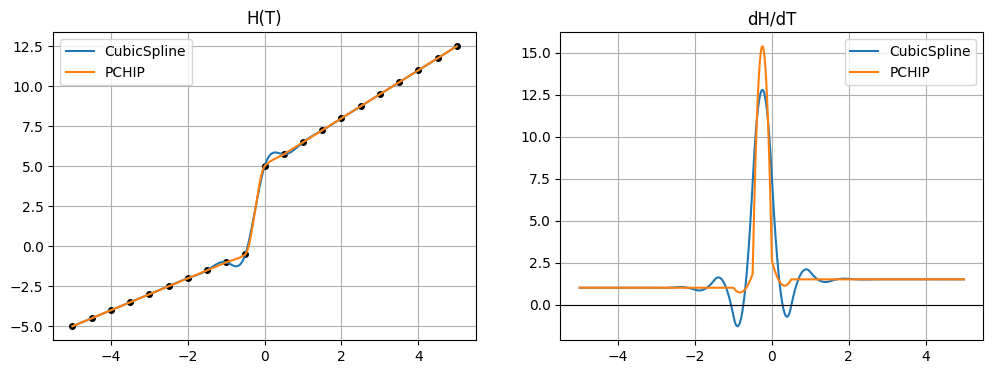

min dH/dT: CubicSpline = -1.2959648484647104 , PCHIP = 0.7222499999999998


In [34]:
from scipy.interpolate import PchipInterpolator

Tk = np.linspace(-5, 5, 21)
Hk = np.where(Tk < 0, 1.0 * Tk, 1.5 * Tk + 5.0)
TT = np.linspace(-5, 5, 2001)
spl, pch = CubicSpline(Tk, Hk), PchipInterpolator(Tk, Hk)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(Tk, Hk, 'ko', ms=4)
ax[0].plot(TT, spl(TT), label='CubicSpline')
ax[0].plot(TT, pch(TT), label='PCHIP')
ax[0].set_title('H(T)'); ax[0].legend()
ax[1].plot(TT, spl(TT, 1), label='CubicSpline')
ax[1].plot(TT, pch(TT, 1), label='PCHIP')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_title('dH/dT'); ax[1].legend()
plt.show()
print('min dH/dT: CubicSpline =', spl(TT, 1).min(), ', PCHIP =', pch(TT, 1).min())

Кубический сплайн на ступеньке осциллирует и даёт участки с $dH/dT < 0$, то есть отрицательную теплоёмкость — физически недопустимо, а в расчёте может привести к неустойчивости. PCHIP строит эрмитов кубический интерполянт с производными в узлах, подобранными так, чтобы сохранялась монотонность данных. Цена — только $C^1$-гладкость и более низкий порядок точности на гладких функциях.

**ДЗ 2.**

not-a-knot : T_max = 3.969 °C, rho_max = 999.970
natural    : T_max = 3.902 °C, rho_max = 999.970


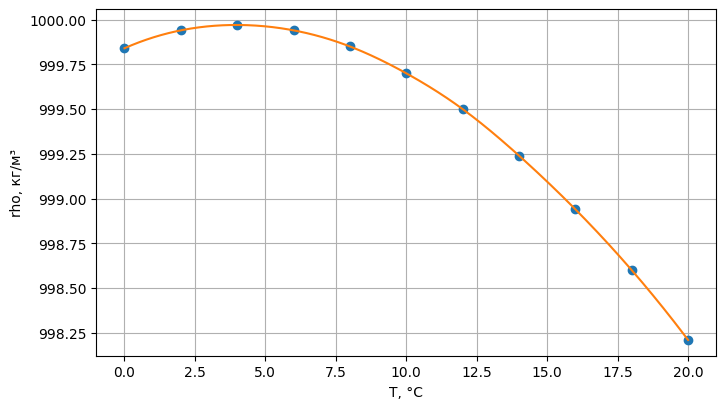

In [35]:
from scipy.optimize import brentq

T_tab = np.arange(0, 21, 2.0)
rho = np.array([999.84, 999.94, 999.97, 999.94, 999.85, 999.70, 999.50, 999.24, 998.94, 998.60, 998.21])
TT = np.linspace(0, 20, 1001)
for bc in ['not-a-knot', 'natural']:
    sp_ = CubicSpline(T_tab, rho, bc_type=bc)
    Tmax = brentq(lambda T: sp_(T, 1), 1.0, 8.0)
    print(f'{bc:11s}: T_max = {Tmax:.3f} °C, rho_max = {sp_(Tmax):.3f}')
plt.plot(T_tab, rho, 'o', TT, CubicSpline(T_tab, rho)(TT))
plt.xlabel('T, °C'); plt.ylabel('rho, кг/м³')
plt.show()

**ДЗ 3.**

In [36]:
tt = np.linspace(0, 1, 20001)
e1, e2 = [], []
for n in ns:
    x = np.linspace(0, 1, n + 1)
    c3 = CubicSpline(x, np.exp(x), bc_type=((1, 1.0), (1, np.e)))
    e1.append(np.max(np.abs(c3(tt, 1) - np.exp(tt))))
    e2.append(np.max(np.abs(c3(tt, 2) - np.exp(tt))))
print("S':");  print_ratios(ns, e1)
print("S'':"); print_ratios(ns, e2)

S':
   n     погрешность   отношение
   4   3.209e-04
   8   4.137e-05       7.76
  16   5.248e-06       7.88
  32   6.606e-07       7.94
  64   8.287e-08       7.97
 128   1.038e-08       7.99
S'':
   n     погрешность   отношение
   4   1.332e-02
   8   3.436e-03       3.88
  16   8.720e-04       3.94
  32   2.196e-04       3.97
  64   5.510e-05       3.99
 128   1.380e-05       3.99


Отношения около 8 для $S'$ ($2^3$, порядок 3) и около 4 для $S''$ ($2^2$, порядок 2).

**ДЗ 4.**

In [37]:
def tridiag_solve(a, b, c, d):
    # Метод прогонки для a_i x_{i-1} + b_i x_i + c_i x_{i+1} = d_i, i = 0..n
    n = len(d) - 1
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    alpha[1] = -c[0] / b[0]
    beta[1] = d[0] / b[0]
    for i in range(1, n):
        den = b[i] + a[i] * alpha[i]
        alpha[i + 1] = -c[i] / den
        beta[i + 1] = (d[i] - a[i] * beta[i]) / den
    x = np.zeros(n + 1)
    x[n] = (d[n] - a[n] * beta[n]) / (b[n] + a[n] * alpha[n])
    for i in range(n - 1, -1, -1):
        x[i] = alpha[i + 1] * x[i + 1] + beta[i + 1]
    return x


rng = np.random.default_rng(0)
N = 50
a_ = rng.uniform(-1, 1, N); a_[0] = 0.0
c_ = rng.uniform(-1, 1, N); c_[-1] = 0.0
b_ = np.abs(a_) + np.abs(c_) + rng.uniform(0.5, 1.5, N)
d_ = rng.uniform(-1, 1, N)
A_full = np.diag(b_) + np.diag(a_[1:], -1) + np.diag(c_[:-1], 1)
print('Отличие от np.linalg.solve:', np.max(np.abs(tridiag_solve(a_, b_, c_, d_) - np.linalg.solve(A_full, d_))))


def natural_spline_tridiag(x, y):
    n = len(x) - 1
    h = np.diff(x)
    a_ = np.zeros(n + 1); b_ = np.ones(n + 1); c_ = np.zeros(n + 1); d_ = np.zeros(n + 1)
    a_[1:n] = h[:-1]
    b_[1:n] = 2.0 * (h[:-1] + h[1:])
    c_[1:n] = h[1:]
    d_[1:n] = 6.0 * (np.diff(y)[1:] / h[1:] - np.diff(y)[:-1] / h[:-1])
    return tridiag_solve(a_, b_, c_, d_)


import time
x = np.linspace(0.0, 1.0, 2001)
y = np.sin(10 * x)
print('Отличие от natural_spline:', np.max(np.abs(natural_spline_tridiag(x, y) - natural_spline(x, y))))
for func in [natural_spline, natural_spline_tridiag]:
    start = time.perf_counter()
    func(x, y)
    print(f'{func.__name__:24s} {time.perf_counter() - start:.4f} с')

Отличие от np.linalg.solve: 1.1102230246251565e-16


Отличие от natural_spline: 2.842170943040401e-14


natural_spline           0.1354 с
natural_spline_tridiag   0.0021 с


Прогонка требует $O(n)$ операций и $O(n)$ памяти, а `np.linalg.solve` для плотной матрицы — $O(n^3)$ операций и $O(n^2)$ памяти, к тому же сборка плотной матрицы в цикле тоже не бесплатна. Хотя прогонка написана на «медленном» Python, а `solve` вызывает оптимизированный LAPACK, при больших $n$ асимптотика побеждает.

**ДЗ 5.**

In [38]:
def clamped_spline(x, y, dfa, dfb):
    n = len(x) - 1
    h = np.diff(x)
    a_ = np.zeros(n + 1); b_ = np.zeros(n + 1); c_ = np.zeros(n + 1); d_ = np.zeros(n + 1)
    a_[1:n] = h[:-1]
    b_[1:n] = 2.0 * (h[:-1] + h[1:])
    c_[1:n] = h[1:]
    d_[1:n] = 6.0 * (np.diff(y)[1:] / h[1:] - np.diff(y)[:-1] / h[:-1])
    b_[0], c_[0], d_[0] = 2.0 * h[0], h[0], 6.0 * ((y[1] - y[0]) / h[0] - dfa)
    a_[n], b_[n], d_[n] = h[-1], 2.0 * h[-1], 6.0 * (dfb - (y[n] - y[n - 1]) / h[-1])
    return tridiag_solve(a_, b_, c_, d_)


x = np.sort(np.concatenate(([0.0, 1.0], np.random.default_rng(2).uniform(0, 1, 9))))
y = np.exp(x)
M = clamped_spline(x, y, 1.0, np.e)
print('Отличие от scipy:', np.max(np.abs(M - CubicSpline(x, y, bc_type=((1, 1.0), (1, np.e)))(x, 2))))

Отличие от scipy: 2.569056078982612e-13


**ДЗ 6.**

равномерная сетка: 0.2803838688194321
сгущённая сетка, лучшее beta = 4.50: 8.305708313782745e-05


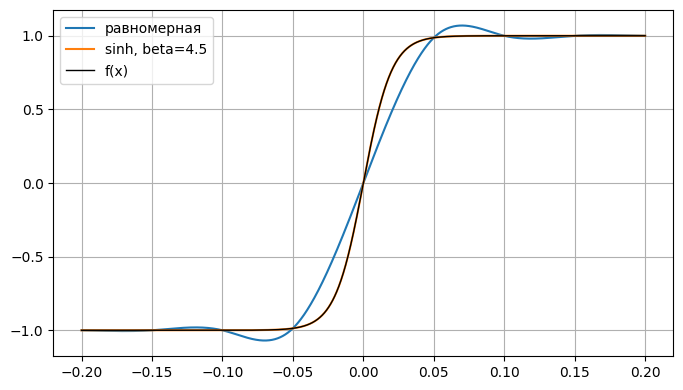

In [39]:
f6 = lambda x: np.tanh(50 * x)
n = 40
xi = np.linspace(-1, 1, n + 1)
tt = np.linspace(-1, 1, 20001)

def err_for(x):
    return np.max(np.abs(CubicSpline(x, f6(x), bc_type='natural')(tt) - f6(tt)))

print('равномерная сетка:', err_for(xi))
betas = np.linspace(0.5, 6, 23)
errs = [err_for(np.sinh(bt * xi) / np.sinh(bt)) for bt in betas]
best = betas[np.argmin(errs)]
print(f'сгущённая сетка, лучшее beta = {best:.2f}:', min(errs))

zoom = np.linspace(-0.2, 0.2, 2001)
for name, x in [('равномерная', xi), (f'sinh, beta={best:.1f}', np.sinh(best * xi) / np.sinh(best))]:
    plt.plot(zoom, CubicSpline(x, f6(x), bc_type='natural')(zoom), label=name)
plt.plot(zoom, f6(zoom), 'k', lw=1, label='f(x)')
plt.legend()
plt.show()

**ДЗ 7.**

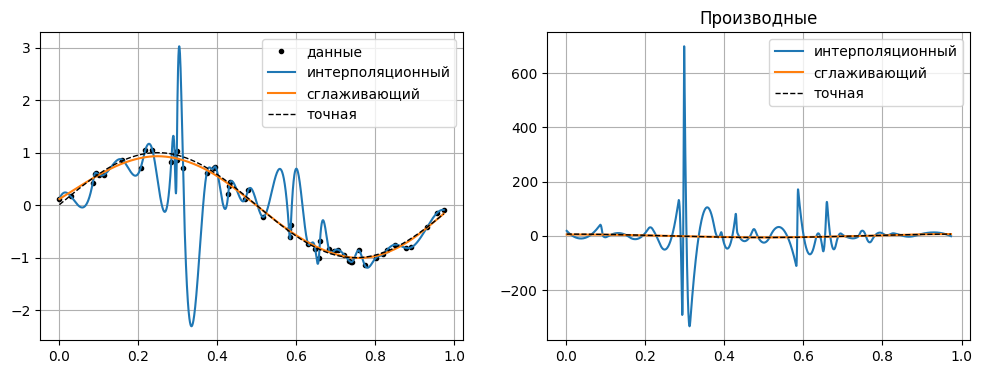

In [40]:
from scipy.interpolate import make_smoothing_spline

rng = np.random.default_rng(3)
xn = np.sort(rng.uniform(0, 1, 50))
yn = np.sin(2 * np.pi * xn) + rng.normal(0, 0.1, xn.size)
tt = np.linspace(xn[0], xn[-1], 2000)
interp, smooth = CubicSpline(xn, yn), make_smoothing_spline(xn, yn)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(xn, yn, 'k.', label='данные')
ax[0].plot(tt, interp(tt), label='интерполяционный')
ax[0].plot(tt, smooth(tt), label='сглаживающий')
ax[0].plot(tt, np.sin(2 * np.pi * tt), 'k--', lw=1, label='точная')
ax[0].legend()
ax[1].plot(tt, interp(tt, 1), label='интерполяционный')
ax[1].plot(tt, smooth(tt, 1), label='сглаживающий')
ax[1].plot(tt, 2 * np.pi * np.cos(2 * np.pi * tt), 'k--', lw=1, label='точная')
ax[1].set_title('Производные'); ax[1].legend()
plt.show()